In [ ]:
# Stock Price Prediction of Bank of America Using Machine Learning and Macroeconomic Indicators

In [7]:
# Import neccessary data science packages
import numpy as np
import pandas as pd
import yfinance as yf

In [2]:
# 'BAC' => Bank of America Corp (peer finance stock)
# 'JPM' => JP Morgan Chase & Co. (peer finance stock)
# 'MS' => Morgan Stanley (peer finance stock)
# 'C' => Citi Group (peer finance stock)
# 'WFC' => Wells Fargo & Co (peer finance stock)
# 'SPY' => S&P500 ETF (Market Index)
# '^VIX' => CBOE Volatility Index (market fear indicator)
# '^TNX' => 10Y US Treasury Yield (Interest Rate Indicator)
# 'DX-Y.NYB' => US Dollar Index (Strength of US Dollar)
# 'CL=F' => # Crude Oil Future (Inflation/energy proxy)
# 'GC=F' => Gold Futures (safe asset)

In [8]:
# Download the data from yahoo finance
tickers = ['BAC','JPM', 'MS', 'C', 'WFC', 'SPY', '^VIX', '^TNX', 'DX-Y.NYB', 'CL=F','GC=F']
data = yf.download(tickers, start = '2015-01-01', end = '2026-01-01')['Close']
data

[*********************100%***********************]  11 of 11 completed


Ticker,BAC,C,CL=F,DX-Y.NYB,GC=F,JPM,MS,SPY,WFC,^TNX,^VIX
Date,,,,,,,,,,,
2015-01-02,13.979472,39.811577,52.689999,91.080002,1186.000000,45.838097,28.250025,169.267578,39.509289,2.123,17.790001
2015-01-05,13.573363,38.556927,50.040001,91.379997,1203.900024,44.415066,27.366983,166.210571,38.425858,2.039,19.920000
2015-01-06,13.167253,37.199532,47.930000,91.500000,1219.300049,43.263412,26.578814,164.645035,37.624115,1.963,21.120001
2015-01-07,13.229735,37.544392,48.650002,91.889999,1210.599976,43.329433,26.958296,166.696671,37.848019,1.954,19.309999
2015-01-08,13.503078,38.109356,48.790001,92.370003,1208.400024,44.297695,27.359680,169.654785,38.685879,2.016,17.010000
...,...,...,...,...,...,...,...,...,...,...,...
2025-12-24,55.362221,119.751472,58.349998,97.980003,4502.799805,322.950073,178.704742,685.029480,93.756538,4.136,13.470000
2025-12-26,55.283482,118.628433,56.740002,98.019997,4552.700195,321.713867,178.921173,684.959961,93.717194,4.136,13.600000
2025-12-29,54.476421,116.372498,58.080002,98.040001,4343.600098,317.632477,177.022476,682.519043,92.989166,4.116,14.200000


In [9]:
# Information about the data
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2771 entries, 2015-01-02 to 2025-12-31
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   BAC       2766 non-null   float64
 1   C         2766 non-null   float64
 2   CL=F      2766 non-null   float64
 3   DX-Y.NYB  2767 non-null   float64
 4   GC=F      2766 non-null   float64
 5   JPM       2766 non-null   float64
 6   MS        2766 non-null   float64
 7   SPY       2766 non-null   float64
 8   WFC       2766 non-null   float64
 9   ^TNX      2765 non-null   float64
 10  ^VIX      2766 non-null   float64
dtypes: float64(11)
memory usage: 259.8 KB


In [10]:
# Statistical Summary of Data
data.describe()

Ticker,BAC,C,CL=F,DX-Y.NYB,GC=F,JPM,MS,SPY,WFC,^TNX,^VIX
count,2766.000000,2766.000000,2766.000000,2767.000000,2766.000000,2766.000000,2766.000000,2766.000000,2766.000000,2765.000000,2766.000000
mean,26.978999,50.821781,62.250907,98.316827,1776.569523,117.633534,60.393083,335.312008,43.883673,2.641337,18.331316
std,10.337156,14.544725,17.362273,4.867837,672.010906,64.896707,35.235681,139.639487,13.216469,1.133843,7.129529
min,8.822169,25.772366,-37.630001,88.589996,1050.800049,39.889202,16.170521,153.779785,18.450834,0.499000,9.140000
25%,19.735043,40.610948,49.487499,94.785000,1272.599976,73.556787,33.330068,217.810329,37.902251,1.768000,13.552500
50%,25.483824,49.469509,61.269999,97.570000,1710.049988,97.746941,42.846992,298.388931,41.048721,2.393000,16.520000
75%,34.171448,57.132136,73.129997,101.834999,1947.850006,138.463356,81.010912,419.840797,45.302176,3.739000,21.247500
max,55.362221,119.751472,123.699997,114.110001,4552.700195,322.950073,178.921173,685.029480,93.756538,4.988000,82.690002


In [11]:
# How many missing values are present in dataset
data.isnull().sum()

Ticker
BAC         5
C           5
CL=F        5
DX-Y.NYB    4
GC=F        5
JPM         5
MS          5
SPY         5
WFC         5
^TNX        6
^VIX        5
dtype: int64

In [12]:
# Appplying forward fill on dataset
data = data.ffill()
data.head()

Ticker,BAC,C,CL=F,DX-Y.NYB,GC=F,JPM,MS,SPY,WFC,^TNX,^VIX
Date,,,,,,,,,,,
2015-01-02,13.979472,39.811577,52.689999,91.080002,1186.000000,45.838097,28.250025,169.267578,39.509289,2.123,17.790001
2015-01-05,13.573363,38.556927,50.040001,91.379997,1203.900024,44.415066,27.366983,166.210571,38.425858,2.039,19.920000
2015-01-06,13.167253,37.199532,47.930000,91.500000,1219.300049,43.263412,26.578814,164.645035,37.624115,1.963,21.120001
2015-01-07,13.229735,37.544392,48.650002,91.889999,1210.599976,43.329433,26.958296,166.696671,37.848019,1.954,19.309999
2015-01-08,13.503078,38.109356,48.790001,92.370003,1208.400024,44.297695,27.359680,169.654785,38.685879,2.016,17.010000


In [13]:
# How many missing values are present in our dataset
data.isnull().sum()

Ticker
BAC         0
C           0
CL=F        0
DX-Y.NYB    0
GC=F        0
JPM         0
MS          0
SPY         0
WFC         0
^TNX        0
^VIX        0
dtype: int64

In [14]:
# Correlation in data
data.corr()

Ticker,BAC,C,CL=F,DX-Y.NYB,GC=F,JPM,MS,SPY,WFC,^TNX,^VIX
Ticker,,,,,,,,,,,
BAC,1.000000,0.821807,0.586651,0.292392,0.834087,0.923329,0.933976,0.932968,0.713925,0.526851,0.052301
C,0.821807,1.000000,0.226395,-0.002912,0.764023,0.842626,0.774187,0.722818,0.841071,0.414076,-0.181061
CL=F,0.586651,0.226395,1.000000,0.461423,0.307004,0.420104,0.528103,0.541041,0.300768,0.564193,-0.048970
DX-Y.NYB,0.292392,-0.002912,0.461423,1.000000,0.336756,0.358679,0.407429,0.438000,0.294457,0.671280,0.096622
GC=F,0.834087,0.764023,0.307004,0.336756,1.000000,0.952014,0.934093,0.928878,0.752040,0.564638,0.124416
JPM,0.923329,0.842626,0.420104,0.358679,0.952014,1.000000,0.966034,0.967064,0.827285,0.655662,0.003268
MS,0.933976,0.774187,0.528103,0.407429,0.934093,0.966034,1.000000,0.973154,0.778130,0.651099,0.041122
SPY,0.932968,0.722818,0.541041,0.438000,0.928878,0.967064,0.973154,1.000000,0.706312,0.638650,0.071506
WFC,0.713925,0.841071,0.300768,0.294457,0.752040,0.827285,0.778130,0.706312,1.000000,0.701580,-0.271305


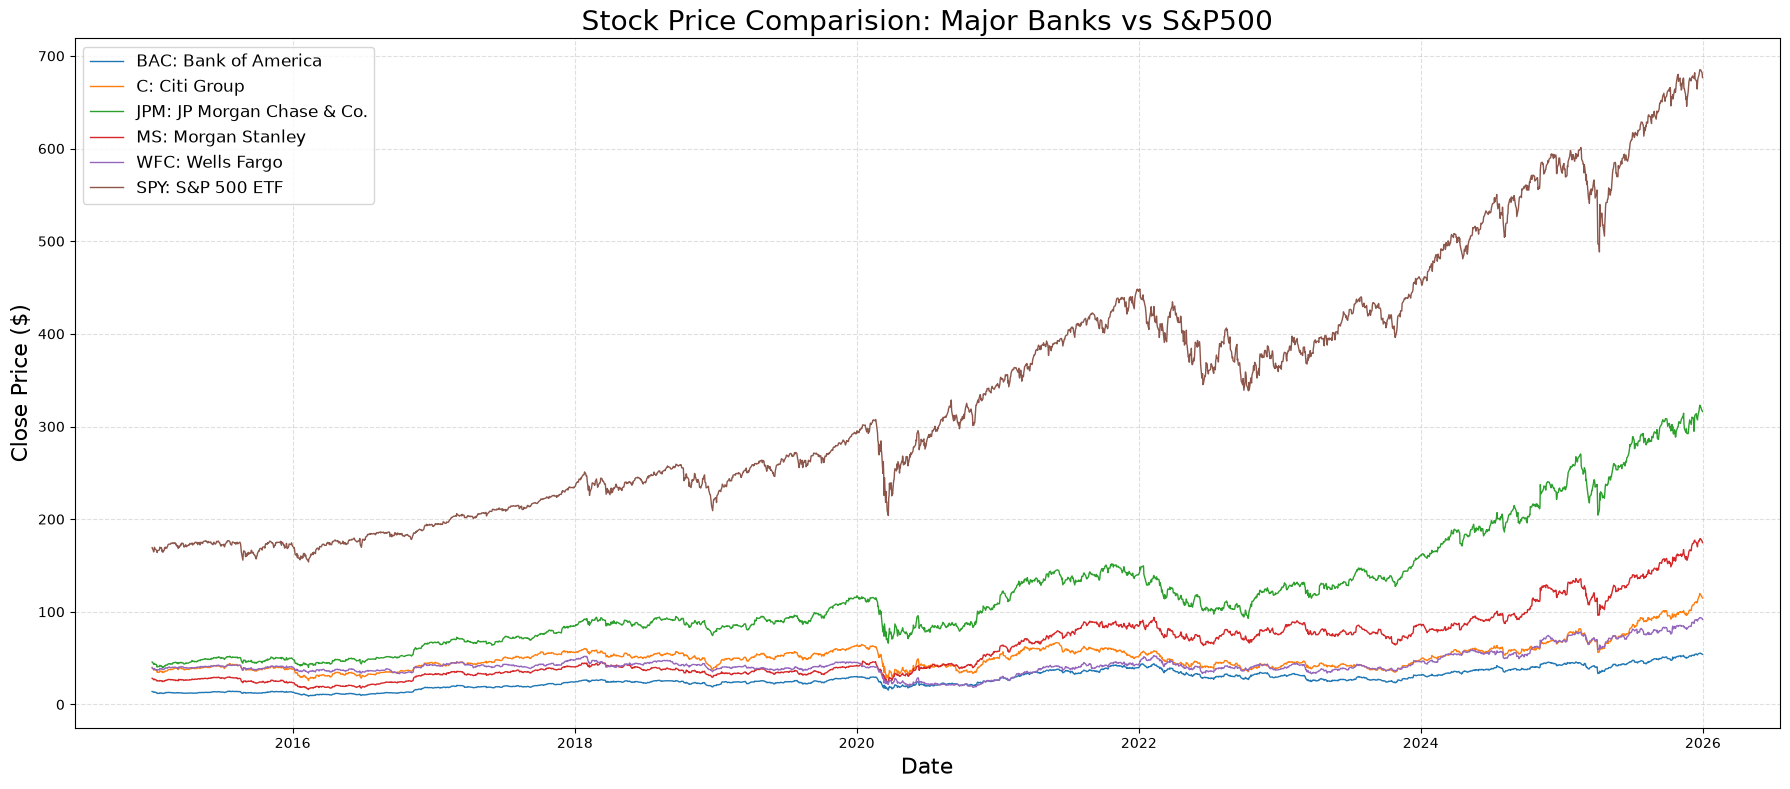

In [15]:
import matplotlib.pyplot as plt
# Create a larger picture
plt.figure(figsize = (18,8))
plt.plot(data.index, data['BAC'], label = 'BAC: Bank of America', linewidth = 1)
plt.plot(data.index, data['C'], label = 'C: Citi Group', linewidth = 1)
plt.plot(data.index, data['JPM'], label = 'JPM: JP Morgan Chase & Co.', linewidth = 1)
plt.plot(data.index, data['MS'], label = 'MS: Morgan Stanley', linewidth = 1)
plt.plot(data.index, data['WFC'], label = 'WFC: Wells Fargo', linewidth = 1)
plt.plot(data.index, data['SPY'], label = 'SPY: S&P 500 ETF', linewidth = 1)
plt.title('Stock Price Comparision: Major Banks vs S&P500', fontsize = 20)
plt.xlabel('Date', fontsize = 16)
plt.ylabel('Close Price ($)', fontsize = 16)
plt.grid(True, linestyle = '--', alpha = 0.4)
plt.legend(fontsize = 12, loc = 'upper left')
plt.tight_layout()
plt.show()

In [16]:
data.head()

Ticker,BAC,C,CL=F,DX-Y.NYB,GC=F,JPM,MS,SPY,WFC,^TNX,^VIX
Date,,,,,,,,,,,
2015-01-02,13.979472,39.811577,52.689999,91.080002,1186.000000,45.838097,28.250025,169.267578,39.509289,2.123,17.790001
2015-01-05,13.573363,38.556927,50.040001,91.379997,1203.900024,44.415066,27.366983,166.210571,38.425858,2.039,19.920000
2015-01-06,13.167253,37.199532,47.930000,91.500000,1219.300049,43.263412,26.578814,164.645035,37.624115,1.963,21.120001
2015-01-07,13.229735,37.544392,48.650002,91.889999,1210.599976,43.329433,26.958296,166.696671,37.848019,1.954,19.309999
2015-01-08,13.503078,38.109356,48.790001,92.370003,1208.400024,44.297695,27.359680,169.654785,38.685879,2.016,17.010000


In [17]:
data.columns

Index(['BAC', 'C', 'CL=F', 'DX-Y.NYB', 'GC=F', 'JPM', 'MS', 'SPY', 'WFC',
       '^TNX', '^VIX'],
      dtype='str', name='Ticker')

In [18]:
# Feature Engineering
df = pd.DataFrame(index = data.index)

# Create lag features - Stock Data
df['JPM(t-1)'] = data['JPM'].shift(1)
df['BAC(t-1)'] = data['BAC'].shift(1)
df['MS(t-1)'] = data['MS'].shift(1)
df['C(t-1)'] = data['C'].shift(1)
df['WFC(t-1)'] = data['WFC'].shift(1)
df['SPY(t-1)'] = data['SPY'].shift(1)

# Create lag features - Macroeconmic Data
df['VIX(t-1)'] = data['^VIX'].shift(1)
df['10Y_Yield(t-1)'] = data['^TNX'].shift(1)
df['Gold_Futures(t-1)'] = data['GC=F'].shift(1)
df['US_Dollar_Index(t-1)'] = data['DX-Y.NYB'].shift(1)
df['Crude_Oil_Futures(t-1)'] = data['CL=F'].shift(1)

# Create Target Variable
df['Target'] = data['BAC']

# Technical Indicators = Moving Average and Rolling Volatility
df['BAC_MA5'] = data['BAC'].rolling(window = 5).mean().shift(1)
df['BAC_MA10'] = data['BAC'].rolling(window = 10).mean().shift(1)
df['BAC_Volatility5'] = data['BAC'].pct_change(5).shift(1)

# Drop nan values
df = df.dropna()
df

,JPM(t-1),BAC(t-1),MS(t-1),C(t-1),WFC(t-1),SPY(t-1),VIX(t-1),10Y_Yield(t-1),Gold_Futures(t-1),US_Dollar_Index(t-1),Crude_Oil_Futures(t-1),Target,BAC_MA5,BAC_MA10,BAC_Volatility5
Date,,,,,,,,,,,,,,,
2015-01-16,40.336647,11.870833,25.236002,34.653526,36.634583,163.985916,22.389999,1.775,1264.699951,92.349998,46.250000,12.011412,12.706479,13.098530,-0.120879
2015-01-20,41.026169,12.011412,25.462238,34.932350,37.299088,166.136429,20.950001,1.815,1276.900024,92.519997,48.689999,11.917694,12.456567,12.901724,-0.094228
2015-01-21,40.864788,11.917694,25.360069,34.675549,37.559097,166.490738,19.889999,1.807,1294.199951,93.050003,46.389999,12.034842,12.234770,12.736157,-0.085132
2015-01-22,40.996819,12.034842,25.345474,35.027729,37.631325,167.331207,18.850000,1.853,1293.699951,92.900002,47.779999,12.565907,12.072328,12.622916,-0.063222
2015-01-23,42.243820,12.565907,25.929298,36.370445,38.837566,169.819595,16.400000,1.896,1300.699951,94.239998,46.310001,12.284754,12.080137,12.556533,0.003117
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-24,319.771271,55.086639,176.589600,117.623611,92.939972,682.628235,14.000000,4.169,4505.700195,97.940002,58.380001,55.362221,54.315012,54.117185,0.021164
2025-12-26,322.950073,55.362221,178.704742,119.751472,93.756538,685.029480,13.470000,4.136,4502.799805,97.980003,58.349998,55.283482,54.649647,54.330760,0.031164
2025-12-29,321.713867,55.283482,178.921173,118.628433,93.717194,684.959961,13.600000,4.136,4552.700195,98.019997,56.740002,54.476421,55.025618,54.489219,0.035201


In [19]:
# a) Tell what is X variables and my Y Variable
X = df.drop('Target', axis = 1)
Y = df['Target']

In [20]:
# b) Split our data into training and testing (90:10)
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, shuffle = False)

In [21]:
# c) Apply ML Algo: Decision Tree
from sklearn.tree import DecisionTreeRegressor
dt_model = DecisionTreeRegressor(max_depth = 4) # Calling the DT Model
dt_model.fit(X_train, Y_train) # Train my DT Model
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators = 100)
rf_model.fit(X_train, Y_train)
from sklearn.neighbors import KNeighborsRegressor
knn_model = KNeighborsRegressor(n_neighbors = 5)
knn_model.fit(X_train, Y_train)
from sklearn.svm import SVR
svr_model = SVR()
svr_model.fit(X_train, Y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [22]:
# d) Do Prediction: X_test and Y_test are my actual values
dt_pred = dt_model.predict(X_test)
rf_pred = rf_model.predict(X_test)
knn_pred = knn_model.predict(X_test)
svr_pred = svr_model.predict(X_test)

In [23]:
# Actual vs Predicted = Decision Tree
result = pd.DataFrame(Y_test.index)
result['Actual'] = Y_test.values
result['DT Prediction'] = dt_pred
result['RF Prediction'] = rf_pred
result['KNN Prediction'] = knn_pred
result['SVR Prediction'] = svr_pred
result

,Date,Actual,DT Prediction,RF Prediction,KNN Prediction,SVR Prediction
0,2023-04-06,25.491449,25.688069,25.165838,29.694670,30.087224
1,2023-04-10,25.583017,25.688069,25.445135,27.579072,30.266874
2,2023-04-11,26.288057,25.688069,25.499360,25.784452,30.539766
3,2023-04-12,26.077456,25.688069,25.966496,27.599216,30.438399
4,2023-04-13,26.150709,25.688069,25.894352,27.579072,30.327858
...,...,...,...,...,...,...
686,2025-12-24,55.362221,41.866757,42.978013,25.909912,14.948954
687,2025-12-26,55.283482,41.866757,42.970500,25.909912,14.953213
688,2025-12-29,54.476421,41.866757,43.015531,25.909912,14.953040
689,2025-12-30,54.407528,41.866757,42.946071,25.909912,14.968851


In [24]:
# e) Evaluate the model based on R2, rmse and mse
from sklearn.metrics import r2_score, mean_squared_error
def evaluate_model(y_true, y_pred, model_name):
    r2 = r2_score(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred) # mse: mean squared error
    rmse = np.sqrt(mse) # rmse: root means sqaured error
    print("Model Name:", model_name)
    print("R2 Value", r2)
    print("MSE", mse)
    print("RMSE", rmse)
    print("\n")

# Y_test = Actual Value
# dt_pred, rf_pred = Predicted Value
evaluate_model(Y_test, dt_pred, "Decision Tree")
evaluate_model(Y_test, rf_pred, "Random Forest")
evaluate_model(Y_test, knn_pred, "K Nearest Neighbor")
evaluate_model(Y_test, svr_pred, "Support Vector Regressor")

Model Name: Decision Tree
R2 Value 0.7936620289096908
MSE 14.6355565726709
RMSE 3.82564459570814


Model Name: Random Forest
R2 Value 0.8496138171870816
MSE 10.66689506868892
RMSE 3.266021290299394


Model Name: K Nearest Neighbor
R2 Value -1.761777049284587
MSE 195.89290343568297
RMSE 13.99617460007137


Model Name: Support Vector Regressor
R2 Value -3.732692291287516
MSE 335.6899624638939
RMSE 18.321843860918964




In [ ]:
# f) Visualtion => Actual vs Forecasted
# Plot figure => tell figure size
plt.figure(figsize = (16,7))

#Plot Actual Value and Predicted Value (X = Date, Y = Stock Price)
plt.plot(Y_test.index, Y_test, label = 'Actual Bank of America Stock Price', linewidth = 2, color ='red',)
plt.plot(Y_test.index, dt_pred, label = 'Decision Tree Prediction', linewidth = 2, color ='black', linestyle = '--')
plt.plot(Y_test.index, rf_pred, label = "Random Forest Prediction", linewidth = 2, color ='blue', linestyle = '--')
plt.plot(Y_test.index, knn_pred, label = "K Nearest Neighbor Prediction", linewidth = 2, color ='orange',)
plt.plot(Y_test.index, svr_pred, label = "Support Vector Regressor Prediction", linewidth = 2, color ='green', linestyle = '--')
    
# Highlight title, xlabel, and ylabel
plt.title("Actual vs Predicted Bank of America Stock Price", fontsize = 18)
plt.xlabel('Date', fontsize = 16)
plt.ylabel('Price ($)', fontsize = 16)
plt.grid(alpha = 0.5)
plt.legend()
plt.show()

In [38]:
# What all features are important?
importance = dt_model.feature_importances_
features_name = X_train.columns

df_features = pd.DataFrame({'Feature':features_name, 'Importance': importance})
df_features = df_features.sort_values(by = 'Importance', ascending = False)
df_features

,Feature,Importance
1,BAC(t-1),0.892009
12,BAC_MA10,0.104794
2,MS(t-1),0.003197
0,JPM(t-1),0.000000
4,WFC(t-1),0.000000
3,C(t-1),0.000000
5,SPY(t-1),0.000000
6,VIX(t-1),0.000000
8,Gold_Futures(t-1),0.000000
7,10Y_Yield(t-1),0.000000


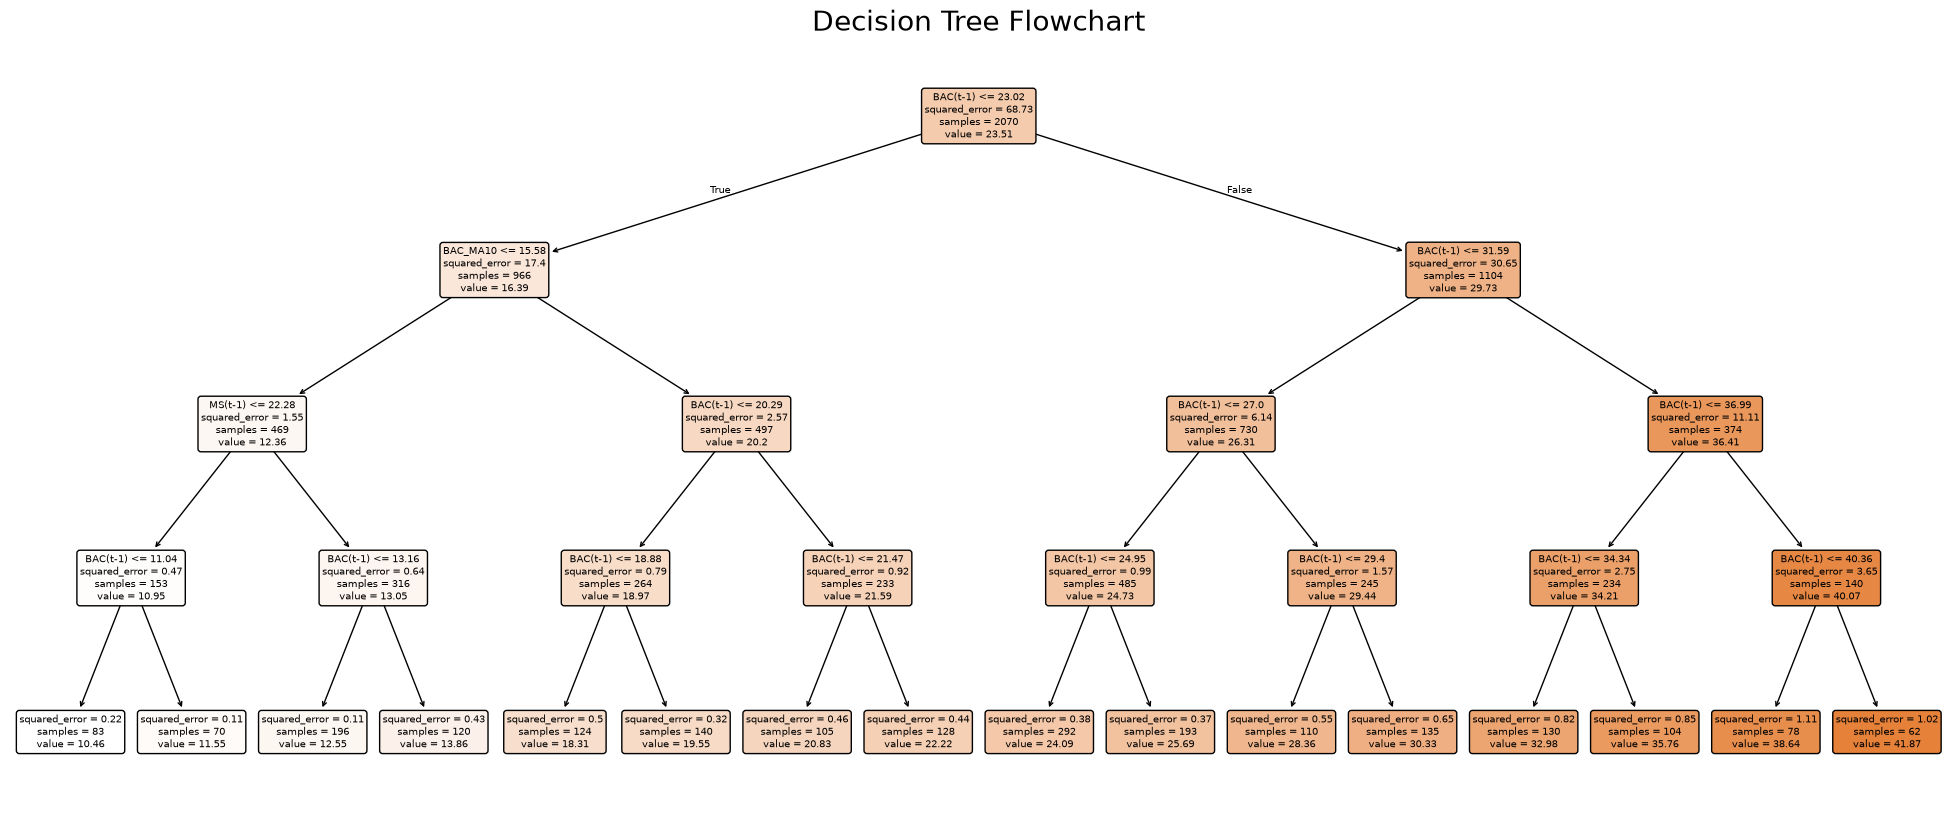

In [39]:
from sklearn.tree import plot_tree

plt.figure(figsize = (25,10))
plot_tree(dt_model, feature_names = X.columns, filled = True, rounded = True, precision = 2)
plt.title("Decision Tree Flowchart", fontsize = 20)
plt.show()